#7.1
## Part (a)

Show that  
$A = \begin{pmatrix}0 & 1 \\ 3 & 2\end{pmatrix}$  
has **no LU factorization** with a unit lower triangular matrix $L$.

Assume:

$L=\begin{pmatrix}
1 & 0\\
\ell_{21} & 1
\end{pmatrix},
\quad
U=\begin{pmatrix}
u_{11} & u_{12}\\
0 & u_{22}
\end{pmatrix}$

Then:

$LU =
\begin{pmatrix}
u_{11} & u_{12} \\
\ell_{21} u_{11} & \ell_{21} u_{12} + u_{22}
\end{pmatrix}
=
\begin{pmatrix}
0 & 1 \\
3 & 2
\end{pmatrix}$

Matching entries gives:

- $u_{11} = 0$
- $u_{12} = 1$
- $\ell_{21} u_{11} = 3$
- $\ell_{21} u_{12} + u_{22} = 2$

But the third equation becomes:

$\ell_{21} \cdot 0 = 3$

which is impossible.

### Therefore, No LU decomposition with unit lower triangular $L$ exists.

In [1]:
# ---- a ----
import sympy as sp

u11, u12, u22, l21 = sp.symbols('u11 u12 u22 l21')

eqs = [
    sp.Eq(u11, 0),
    sp.Eq(u12, 1),
    sp.Eq(l21*u11, 3),
    sp.Eq(l21*u12 + u22, 2)
]

sp.solve(eqs, (u11, u12, u22, l21), dict=True)


[]

## Part (b)

Let $P$ be a permutation matrix that swaps rows $i_1$ and $i_2$.

### Show that $PA$ swaps the rows of $A$

Left-multiplying a matrix by a permutation matrix reorders its rows:

- Row $i_1$ becomes row $i_2$
- Row $i_2$ becomes row $i_1$
- All other rows stay the same

Thus:

### $PA$ is $A$ with rows $i_1$ and $i_2$ swapped.

---

### Show that $P^{-1} = P^T = P$

Properties of permutation matrices:

- $P^2 = I$ (swapping twice restores the original order)
- Therefore $P^{-1} = P$
- Permutation matrices are symmetric: $P^T = P$

Thus:

### $P^{-1} = P^T = P$

In [2]:
import numpy as np

P = np.array([[0,1],
              [1,0]], float)

A = np.array([[0,1],
              [3,2]], float)

PA = P @ A

print("P =\n", P)
print("PA =\n", PA)
print("P^T =\n", P.T)
print("P @ P =\n", P @ P)


P =
 [[0. 1.]
 [1. 0.]]
PA =
 [[3. 2.]
 [0. 1.]]
P^T =
 [[0. 1.]
 [1. 0.]]
P @ P =
 [[1. 0.]
 [0. 1.]]


## Part (c)

Given the LU factorization with pivoting:

$PA = LU$

Solve the system $Ax=b$.

Start with:

$Ax = b$

Left multiply by $P$:

$PAx = Pb$

Substitute $PA = LU$:

$LUx = Pb$

Define:

$Ly = Pb$

Then:

$Ux = y$

This gives the final solution $x$.

In [3]:
import numpy as np
import scipy.linalg as la

A = np.array([[0.,1.],
              [3.,2.]])
b = np.array([1.,1.])

P = np.array([[0.,1.],
              [1.,0.]])

# PA is upper triangular for this matrix
PA = P @ A
L = np.eye(2)
U = PA.copy()

Pb = P @ b

# Forward substitution
y = la.solve_triangular(L, Pb, lower=True)

# Backward substitution
x = la.solve_triangular(U, y)

print("Solution x =", x)
print("Check A x =", A @ x)


Solution x = [-0.33333333  1.        ]
Check A x = [1. 1.]


#7.2


n = 10


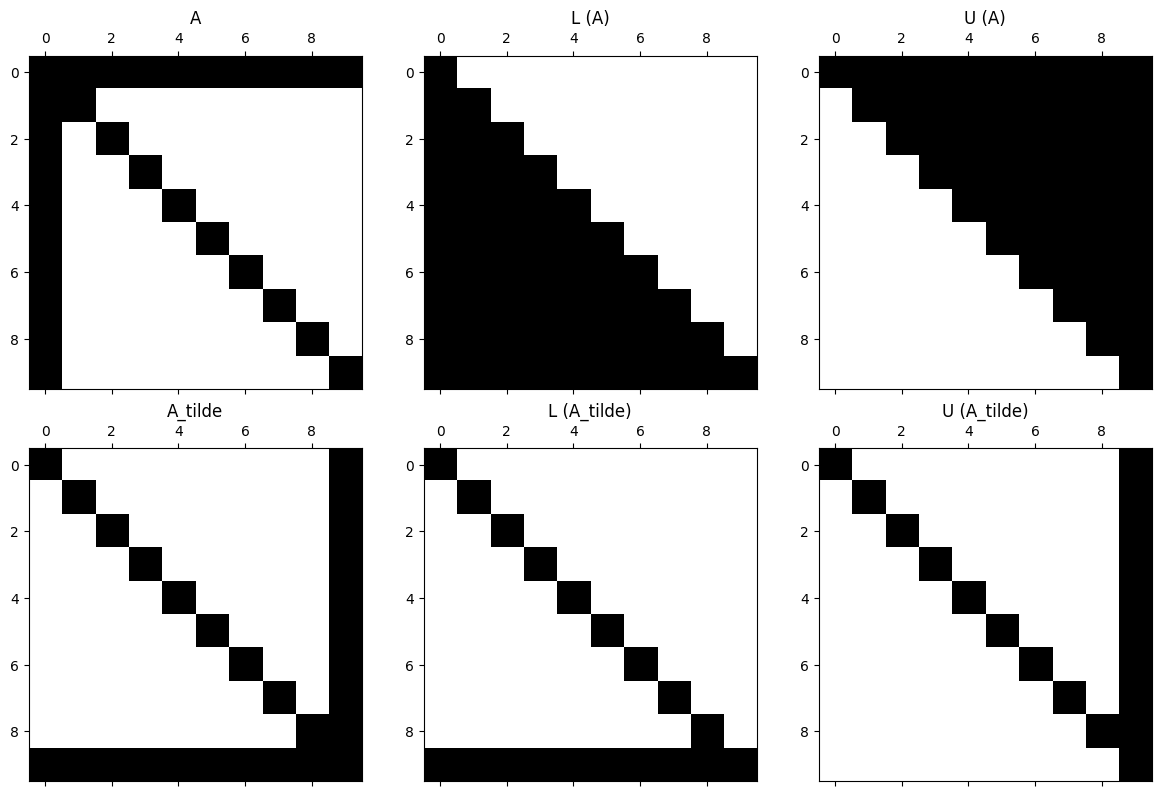

Original ordering (A):          110 nonzeros in L+U
Reversed ordering (A_tilde):     38 nonzeros in L+U
Sparse NATURAL ordering:        110 nonzeros in L+U
RCM ordering:                    38 nonzeros in L+U
AMD (COLAMD) ordering:          110 nonzeros in L+U

Best method for n=10: Dense reversed with 38 nonzeros

n = 100
Original ordering (A):        10100 nonzeros in L+U
Reversed ordering (A_tilde):    398 nonzeros in L+U
Sparse NATURAL ordering:      10100 nonzeros in L+U
RCM ordering:                   398 nonzeros in L+U
AMD (COLAMD) ordering:        10100 nonzeros in L+U

Best method for n=100: Dense reversed with 398 nonzeros

n = 1000
Original ordering (A):       977260 nonzeros in L+U
Reversed ordering (A_tilde):   3998 nonzeros in L+U
Sparse NATURAL ordering:     1001000 nonzeros in L+U
RCM ordering:                  3998 nonzeros in L+U
AMD (COLAMD) ordering:         3998 nonzeros in L+U

Best method for n=1000: Dense reversed with 3998 nonzeros

Analysis complete!


In [4]:
# Arrowhead matrix experiment for Exercise 7.2

import numpy as np
import matplotlib.pyplot as plt
import scipy.linalg as la
import scipy.sparse as sparse
from scipy.sparse.linalg import splu
from scipy.sparse.csgraph import reverse_cuthill_mckee

def arrowhead_matrix(n):
    """Dense arrowhead matrix A = 10I + b e^T + e b^T."""
    e = np.ones(n)
    b = np.zeros(n)
    b[0] = 1.0
    A = 10 * np.eye(n) + np.outer(b, e) + np.outer(e, b)
    return A

for n in [10, 100, 1000]:
    print("\n" + "=" * 60)
    print(f"n = {n}")
    print("=" * 60)

    # Build A and Â (reversed rows/cols)
    A = arrowhead_matrix(n)
    A_tilde = A[::-1, ::-1]   # reverse rows and columns

    # Dense LU (no pivoting control, just for visualization / baseline)
    P, L, U = la.lu(A)
    P_tilde, L_tilde, U_tilde = la.lu(A_tilde)

    # Plot sparsity pattern only for n = 10 (otherwise too big)
    if n == 10:
        fig, axs = plt.subplots(2, 3, figsize=(12, 8))

        axs[0, 0].spy(A)
        axs[0, 0].set_title("A")
        axs[0, 1].spy(L)
        axs[0, 1].set_title("L (A)")
        axs[0, 2].spy(U)
        axs[0, 2].set_title("U (A)")

        axs[1, 0].spy(A_tilde)
        axs[1, 0].set_title("A_tilde")
        axs[1, 1].spy(L_tilde)
        axs[1, 1].set_title("L (A_tilde)")
        axs[1, 2].spy(U_tilde)
        axs[1, 2].set_title("U (A_tilde)")

        plt.tight_layout()
        plt.show()

    # Count non-zeros (dense LU)
    nnz_LU = np.count_nonzero(L) + np.count_nonzero(U)
    nnz_LU_tilde = np.count_nonzero(L_tilde) + np.count_nonzero(U_tilde)

    print(f"Original ordering (A):       {nnz_LU:6d} nonzeros in L+U")
    print(f"Reversed ordering (A_tilde): {nnz_LU_tilde:6d} nonzeros in L+U")

    # Sparse LU with different orderings: natural, RCM, AMD(COLAMD)
    A_sparse = sparse.csc_matrix(A)

    # Natural ordering (for comparison to others)
    lu_nat = splu(A_sparse, permc_spec="NATURAL")
    nnz_nat = lu_nat.L.nnz + lu_nat.U.nnz
    print(f"Sparse NATURAL ordering:     {nnz_nat:6d} nonzeros in L+U")

    # Reverse Cuthill-McKee
    try:
        rcm_perm = reverse_cuthill_mckee(A_sparse, symmetric_mode=True)
        A_rcm = A_sparse[rcm_perm, :][:, rcm_perm]
        lu_rcm = splu(A_rcm, permc_spec="NATURAL")
        nnz_rcm = lu_rcm.L.nnz + lu_rcm.U.nnz
        print(f"RCM ordering:                {nnz_rcm:6d} nonzeros in L+U")
    except Exception as e:
        nnz_rcm = np.inf
        print(f"RCM ordering failed: {e}")

    # Approximate minimum degree via COLAMD
    try:
        lu_amd = splu(A_sparse, permc_spec="COLAMD")
        nnz_amd = lu_amd.L.nnz + lu_amd.U.nnz
        print(f"AMD (COLAMD) ordering:       {nnz_amd:6d} nonzeros in L+U")
    except Exception as e:
        nnz_amd = np.inf
        print(f"AMD ordering failed: {e}")

    # Determine which ordering gives the fewest nonzeros
    methods = ["Dense original", "Dense reversed",
               "Sparse NATURAL", "RCM", "AMD(COLAMD)"]
    nnz_values = [nnz_LU, nnz_LU_tilde, nnz_nat, nnz_rcm, nnz_amd]

    valid = [(m, v) for m, v in zip(methods, nnz_values) if np.isfinite(v)]
    if valid:
        best_method, best_nnz = min(valid, key=lambda x: x[1])
        print(f"\nBest method for n={n}: {best_method} with {best_nnz} nonzeros")

print("\n" + "=" * 60)
print("Analysis done!")
print("=" * 60)


# Exercise 7.4

We consider the matrix

$A =
\begin{pmatrix}
4 & -2 & 2 \\
-2 & 1.001 & 3 \\
2 & -2 & 2
\end{pmatrix},
\qquad
b =
\begin{pmatrix}
4 \\ 7 \\ 6
\end{pmatrix}.
$

---

# (a) LU factorization without pivoting

We eliminate below the first pivot $4$.

### Step 1: Compute $l_{21}$

$l_{21} = \frac{-2}{4} = -\frac{1}{2}$.

Apply elimination:

$A_1 =
\begin{pmatrix}
4 & -2 & 2 \\
0 & 0.001 & 4 \\
2 & -2 & 2
\end{pmatrix},
\qquad
b_1 =
\begin{pmatrix}
4 \\ 7 \\ 6
\end{pmatrix}.
$

---

### Step 2: Compute $l_{31}$

$l_{31} = \frac{2}{4} = \frac{1}{2}$.

Apply elimination:

$A_2 =
\begin{pmatrix}
4 & -2 & 2 \\
0 & 0.001 & 4 \\
0 & -1 & 1
\end{pmatrix},
\qquad
b_2 =
\begin{pmatrix}
4 \\ 7 \\ 4
\end{pmatrix}.
$

---

### Step 3: Compute $l_{32}$

$l_{32} = \frac{-1}{0.001} = -10^{3}$.

Apply elimination:

$A_3 =
\begin{pmatrix}
4 & -2 & 2 \\
0 & 0.001 & 4 \\
0 & 0 & 4001
\end{pmatrix},
\qquad
b_3 =
\begin{pmatrix}
4 \\ 7 \\ 7004
\end{pmatrix}.
$

Thus:

$L =
\begin{pmatrix}
1 & 0 & 0 \\
-\frac{1}{2} & 1 & 0 \\
\frac{1}{2} & -10^{3} & 1
\end{pmatrix},
\qquad
U =
\begin{pmatrix}
4 & -2 & 2 \\
0 & 0.001 & 4 \\
0 & 0 & 4001
\end{pmatrix}.
$

---

# Solving $LUx = b$

Back substitution:

### Step 1: Solve for $x_3$

$4001\, x_3 = 7004  
\Rightarrow x_3 = \frac{7004}{4001}.$

### Step 2: Solve for $x_2$

$0.001\, x_2 + 4 x_3 = 7  
\Rightarrow x_2 = \frac{7 - 4 x_3}{0.001} = -\frac{9000}{4001}.$

### Step 3: Solve for $x_1$

$4 x_1 - 2 x_2 + 2 x_3 = 4  
\Rightarrow x_1 = -1.$

Thus:

$x =
\begin{pmatrix}
-1 \\
-\frac{9000}{4001} \\
\frac{7004}{4001}
\end{pmatrix}.
$

### Numerical stability comment

This factorization is **numerically unstable** because the pivot $0.001$ is extremely small, making the solution overly sensitive to small perturbations in $A$ or $b$.

---

# (b) LU factorization with **row pivoting**

We swap rows 2 and 3 first (to avoid the tiny pivot).

$B =
\begin{pmatrix}
4 & -2 & 2 \\
2 & -2 & 2 \\
-2 & 1.001 & 3
\end{pmatrix},
\qquad
b =
\begin{pmatrix}
4 \\ 5 \\ 6
\end{pmatrix}.
$

Now perform LU:

### Step 1: $l_{21} = \frac{2}{4} = \frac{1}{2}$

### Step 2: $l_{31} = \frac{-2}{4} = -\frac{1}{2}$

After elimination:

$B_1 =
\begin{pmatrix}
4 & -2 & 2 \\
0 & -1 & 1 \\
0 & 0 & 4.001
\end{pmatrix},
\qquad
b_1 =
\begin{pmatrix}
4 \\ 4 \\ 7
\end{pmatrix}.
$

Now $l_{32} = \frac{0}{-1} = 0$  
(no instability here).

Thus:

$L =
\begin{pmatrix}
1 & 0 & 0 \\
\frac{1}{2} & 1 & 0 \\
-\frac{1}{2} & 0 & 1
\end{pmatrix},
\qquad
U =
\begin{pmatrix}
4 & -2 & 2 \\
0 & -1 & 1 \\
0 & 0 & 4.001
\end{pmatrix}.
$

---

# Solve $LUx = Pb$

Back substitution:

$x_3 = \frac{7}{4.001} \approx \frac{7004}{4001}$  
$x_2 = -\frac{9000}{4001}$  
$x_1 = -1$

So:

$x =
\begin{pmatrix}
-1 \\
-\frac{9000}{4001} \\
\frac{7004}{4001}
\end{pmatrix}.
$

### Stability comment

After pivoting, **all pivots are large**, and the factorization is **numerically stable**.  
The solution is the same, but now the method is robust.

---


# Exercise 7.5

Let $Q$ be an orthogonal matrix, meaning  
$Q^T Q = QQ^T = I$.

---

## (a) Show that $\|Qx\|_2 = \|x\|_2$ for all $x \in \mathbb{R}^n$.

Using $\|v\|_2^2 = v^T v$:

$\|Qx\|_2^2 = (Qx)^T (Qx)  
= x^T Q^T Q x  
= x^T I x  
= x^T x  
= \|x\|_2^2.$

Since both sides are non-negative:

$\boxed{\|Qx\|_2 = \|x\|_2.}$

Thus orthogonal matrices preserve the Euclidean norm.

---

## (b) Show that $x^T y = (Qx)^T (Qy)$ for all $x,y\in\mathbb{R}^n$.

Compute:

$(Qx)^T (Qy)  
= x^T Q^T Q y  
= x^T I y  
= x^T y.$

Therefore:

$\boxed{x^T y = (Qx)^T (Qy).}$

Orthogonal matrices preserve inner products.

---

## (c) Let $A \in \mathbb{R}^{m\times n}$ with $m>n$ and QR factorization $A = QR$.  
Show: If $A$ has full column rank ($\operatorname{rank}(A)=n$), then the diagonal entries of $R$ are non-zero.

Since $Q$ is orthogonal, $Q^{-1} = Q^T$, so:

$R = Q^T A.$

Left-multiplying by an invertible matrix does not change rank:

$\operatorname{rank}(R) = \operatorname{rank}(Q^T A) = \operatorname{rank}(A) = n.$

But $R$ is an $n \times n$ upper triangular matrix.  
A triangular matrix has full rank if and only if all diagonal entries are non-zero.

If any diagonal entry $r_{ii} = 0$, then $\det(R)=0$ because the determinant of a triangular matrix is the product of its diagonal entries, implying $\operatorname{rank}(R) < n$ — contradiction.

Thus all diagonal entries must be non-zero:

$\boxed{r_{11}, r_{22}, \dots, r_{nn} \neq 0.}$

This completes the proof.
